# Stage 4 — Machine Learning Model Training & Comparison

**Project:** Customer Churn Prediction + Explainable AI  
**Stage:** 4 — Baseline Model Training & Performance Comparison  

### Objectives for Stage 4:
1. **Reproduce Stage 3 Preprocessing**: Reload raw dataset and `models/preprocessor.joblib`, applying identical feature engineering (`AverageMonthlySpend`, `ServiceCount`) and an 80/20 stratified train/test split.
2. **Train Three Baseline Models**:
   - **Logistic Regression**: Linear baseline.
   - **Random Forest**: Ensembled bagging baseline.
   - **XGBoost**: Gradient boosting baseline.
3. **Evaluate & Compare Models**: Calculate Accuracy, Precision, Recall, F1-Score, and ROC-AUC.
4. **Visualize Model Performance**: Generate Confusion Matrices, combined ROC Curves, and combined Precision-Recall Curves.
5. **Analyze Feature Importances**: Extract top 15–20 Gini/Gain feature importances for tree models and contrast with SHAP.
6. **Business Risk & Threshold Analysis**: Analyze False Negative costs, threshold shifts (0.50 vs 0.30), and present a 1,000-customer retention intervention scenario.
7. **Serialize Models**: Save trained model artifacts to `models/` using `joblib`.
8. **Integrity Assertions**: Verify prediction ranges, reloadability, and zero test leakage.

## Part 1 & 2: Environment Setup & Reproducible Data Pipeline

We import essential modeling libraries, load the raw dataset and saved preprocessor (`models/preprocessor.joblib`), and apply the exact feature engineering logic established in Stage 3.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os

# Machine Learning & Evaluation Imports
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, classification_report, roc_curve, precision_recall_curve
)

# Set style & plot options
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
pd.set_option('display.max_columns', None)

# Load raw dataset and saved preprocessor
raw_csv_path = '../data/telco_customer_churn.csv'
preprocessor_path = '../models/preprocessor.joblib'

df = pd.read_csv(raw_csv_path)
preprocessor = joblib.load(preprocessor_path)

print('Dataset loaded:', df.shape)
print('Preprocessor loaded successfully:', type(preprocessor))

Dataset loaded: (7043, 21)
Preprocessor loaded successfully: <class 'sklearn.compose._column_transformer.ColumnTransformer'>


## Part 3 & 4: Feature Engineering, Target Preparation & Stratified Split

We apply identical feature engineering to derive `AverageMonthlySpend` and `ServiceCount`, convert target `Churn` to binary integers (`0` / `1`), and perform an 80/20 stratified split (`random_state=42`).

In [2]:
# Coerce TotalCharges to numeric
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# Feature Engineering Function (Exact Stage 3 Logic)
def engineer_features(data):
    df_eng = data.copy()
    df_eng['AverageMonthlySpend'] = np.where(
        df_eng['tenure'] > 0, 
        df_eng['TotalCharges'] / df_eng['tenure'], 
        df_eng['MonthlyCharges']
    )
    services = [
        'PhoneService', 'MultipleLines', 'InternetService', 
        'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 
        'TechSupport', 'StreamingTV', 'StreamingMovies'
    ]
    service_count = pd.Series(0, index=df_eng.index)
    for col in services:
        active_mask = ~df_eng[col].isin(['No', 'No phone service', 'No internet service'])
        service_count += active_mask.astype(int)
    df_eng['ServiceCount'] = service_count
    return df_eng

# Separate features and target
X = df.drop(columns=['customerID', 'Churn']).copy()
y = df['Churn'].map({'No': 0, 'Yes': 1}).astype(int)

# Verify target classes
print('Target values check:', set(np.unique(y)))
assert set(np.unique(y)) == {0, 1}, 'Target encoding invalid!'

# Stratified 80/20 Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Apply Feature Engineering separately
X_train_eng = engineer_features(X_train)
X_test_eng = engineer_features(X_test)

# Transform features using saved preprocessor
X_train_processed = preprocessor.transform(X_train_eng)
X_test_processed = preprocessor.transform(X_test_eng)
feature_names = preprocessor.get_feature_names_out()

print(f'X_train_processed shape: {X_train_processed.shape}')
print(f'X_test_processed shape:  {X_test_processed.shape}')
print(f'Transformed feature count: {len(feature_names)}')

Target values check: {np.int64(0), np.int64(1)}
X_train_processed shape: (5634, 47)
X_test_processed shape:  (1409, 47)
Transformed feature count: 47


## Part 5 — Model 1: Logistic Regression

### What Logistic Regression Does:
- Models the probability of binary churn $P(Y=1|X)$ using the sigmoid function: $\sigma(z) = \frac{1}{1 + e^{-z}}$, where $z = \beta_0 + \beta_1 X_1 + \dots + \beta_k X_k$.
- **Baseline Role:** Highly interpretable linear baseline; provides log-odds coefficients and smooth calibrated probabilities.
- **Configuration:** `max_iter=1000` to guarantee numerical solver convergence.

In [3]:
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train_processed, y_train)

lr_pred = lr_model.predict(X_test_processed)
lr_proba = lr_model.predict_proba(X_test_processed)[:, 1]
print('Logistic Regression training complete!')

Logistic Regression training complete!


C:\ProgramData\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


## Part 6 — Model 2: Random Forest

### What Random Forest Does:
- An ensemble bagging algorithm combining $N$ decision trees trained on bootstrap samples.
- **Variance Reduction:** Individual decision trees have high variance and overfit easily; averaging predictions across 100 decorrelated trees reduces variance substantially.
- **Feature Subsampling:** Selects a random subset of features at each split node, capturing non-linear feature interactions without greedy dominance.

In [4]:
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train_processed, y_train)

rf_pred = rf_model.predict(X_test_processed)
rf_proba = rf_model.predict_proba(X_test_processed)[:, 1]
print('Random Forest training complete!')

Random Forest training complete!


## Part 7 — Model 3: XGBoost

### What XGBoost Does:
- A sequential Gradient Boosting decision tree algorithm that builds shallow trees sequentially.
- **Residual Error Correction:** Each new tree $h_m(x)$ is trained specifically to minimize the residual loss (error) of the ensemble of previous trees.
- **Tabular Dominance:** Incorporates L1/L2 regularization and tree pruning, making it state-of-the-art for structured tabular datasets.

In [5]:
xgb_model = XGBClassifier(
    n_estimators=100, learning_rate=0.1, random_state=42, 
    eval_metric='logloss', use_label_encoder=False
)
xgb_model.fit(X_train_processed, y_train)

xgb_pred = xgb_model.predict(X_test_processed)
xgb_proba = xgb_model.predict_proba(X_test_processed)[:, 1]
print('XGBoost training complete!')

XGBoost training complete!


C:\Users\eluri surya vamsi\AppData\Roaming\Python\Python313\site-packages\xgboost\training.py:183: UserWarning: [02:19:40] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


## Part 8 & 9: Predictions & Comparative Evaluation Metrics

We evaluate all three baseline models on the test set (`1,409` samples) across Accuracy, Precision, Recall, F1-Score, and ROC-AUC.

In [6]:
def calculate_metrics(y_true, y_pred, y_proba):
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred),
        'Recall': recall_score(y_true, y_pred),
        'F1-Score': f1_score(y_true, y_pred),
        'ROC-AUC': roc_auc_score(y_true, y_proba)
    }

metrics_dict = {
    'Logistic Regression': calculate_metrics(y_test, lr_pred, lr_proba),
    'Random Forest': calculate_metrics(y_test, rf_pred, rf_proba),
    'XGBoost': calculate_metrics(y_test, xgb_pred, xgb_proba)
}

metrics_df = pd.DataFrame(metrics_dict).T.round(4)
print('=== Baseline Model Comparison Table ===')
display(metrics_df)

=== Baseline Model Comparison Table ===


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Logistic Regression,0.8048,0.6562,0.5561,0.6020,0.8421
Random Forest,0.7885,0.6293,0.4947,0.5539,0.8195
XGBoost,0.7935,0.6361,0.5187,0.5714,0.8363


## Part 10: Confusion Matrix Analysis

### Understanding Confusion Matrix Quadrants:
- **True Negative (TN):** Retained customer correctly predicted as Retained.
- **True Positive (TP):** Churned customer correctly predicted as Churned.
- **False Positive (FP):** Retained customer incorrectly predicted as Churned (wasted retention offer cost).
- **False Negative (FN):** Churned customer incorrectly predicted as Retained (**CRITICAL RISK**: customer leaves unnoticed, causing lifetime value revenue loss).

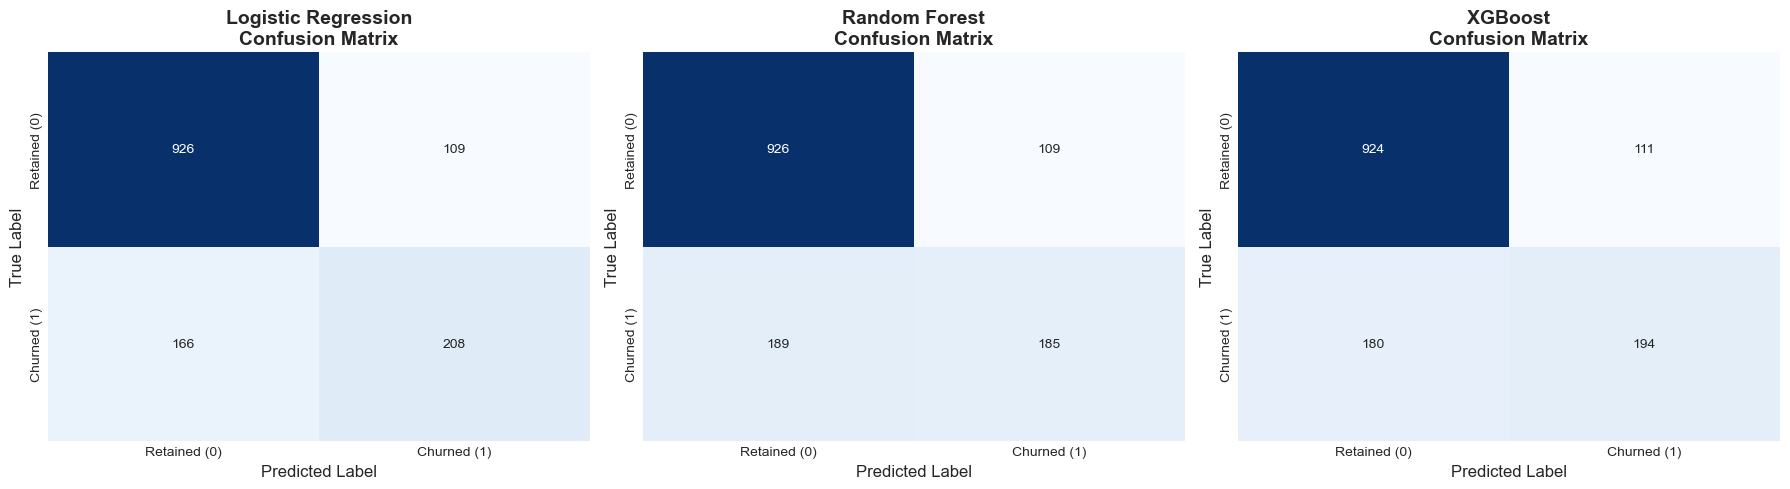

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
models = [('Logistic Regression', lr_pred), ('Random Forest', rf_pred), ('XGBoost', xgb_pred)]

for idx, (name, pred) in enumerate(models):
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[idx],
                xticklabels=['Retained (0)', 'Churned (1)'],
                yticklabels=['Retained (0)', 'Churned (1)'], cbar=False)
    axes[idx].set_title(f'{name}\nConfusion Matrix', fontsize=14, fontweight='bold')
    axes[idx].set_xlabel('Predicted Label', fontsize=12)
    axes[idx].set_ylabel('True Label', fontsize=12)

plt.tight_layout()
plt.show()

## Part 11: Detailed Classification Reports

We inspect per-class precision and recall, focusing on Positive Class (`Churn = 1`).

In [8]:
for name, pred in [('Logistic Regression', lr_pred), ('Random Forest', rf_pred), ('XGBoost', xgb_pred)]:
    print(f'=== Classification Report: {name} ===')
    print(classification_report(y_test, pred, target_names=['Retained (0)', 'Churned (1)']))
    print('-'*55)

=== Classification Report: Logistic Regression ===
              precision    recall  f1-score   support

Retained (0)       0.85      0.89      0.87      1035
 Churned (1)       0.66      0.56      0.60       374

    accuracy                           0.80      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.80      0.80      1409

-------------------------------------------------------
=== Classification Report: Random Forest ===
              precision    recall  f1-score   support

Retained (0)       0.83      0.89      0.86      1035
 Churned (1)       0.63      0.49      0.55       374

    accuracy                           0.79      1409
   macro avg       0.73      0.69      0.71      1409
weighted avg       0.78      0.79      0.78      1409

-------------------------------------------------------
=== Classification Report: XGBoost ===
              precision    recall  f1-score   support

Retained (0)       0.84      0.89      0.86 

## Part 12 & 13: ROC & Precision-Recall Curves

- **ROC Curve (Receiver Operating Characteristic):** Plots True Positive Rate (Recall) vs False Positive Rate ($1 - \text{Specificity}$). ROC-AUC measures overall ranking separation across all thresholds.
- **Precision-Recall Curve:** Plots Precision vs Recall. Especially informative for imbalanced positive classes (~26.5% churn), where high true negative counts can inflate ROC curves.

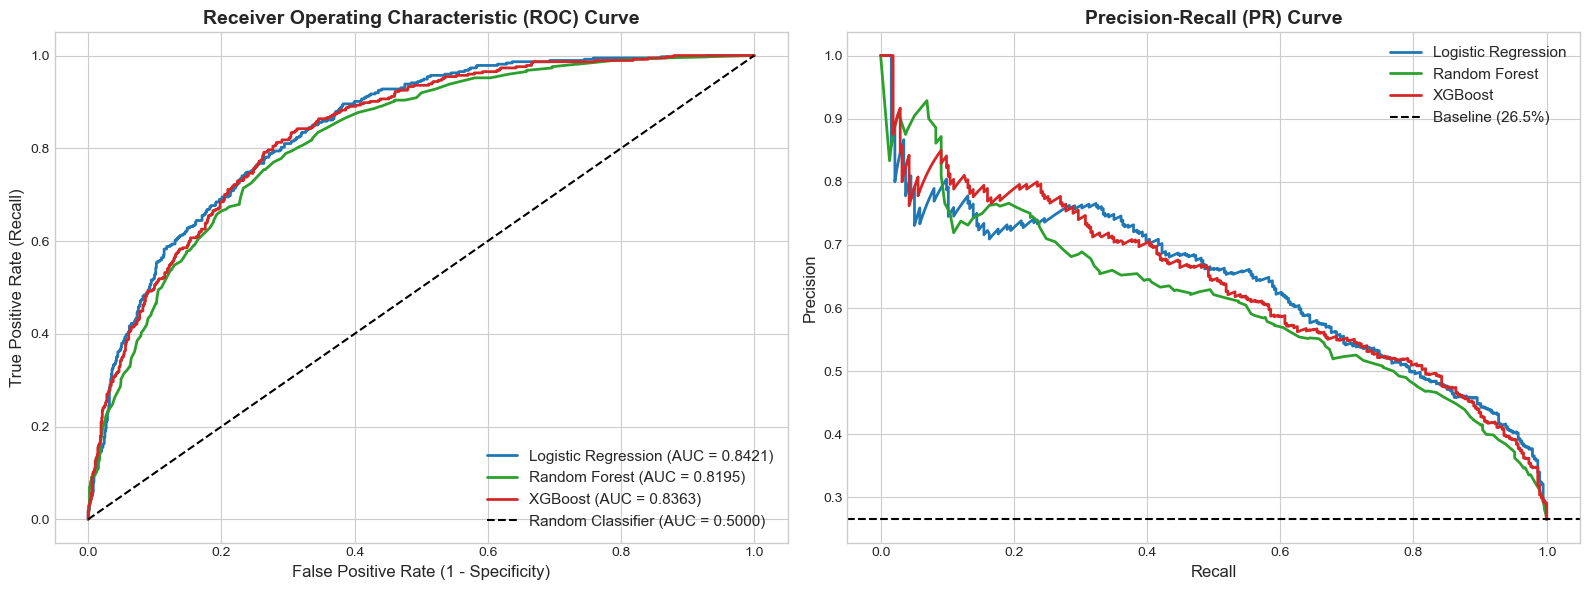

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(16, 6))

# 1. ROC Curves
probas = [('Logistic Regression', lr_proba, '#1f77b4'), ('Random Forest', rf_proba, '#2ca02c'), ('XGBoost', xgb_proba, '#d62728')]
for name, proba, color in probas:
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc_val = roc_auc_score(y_test, proba)
    ax[0].plot(fpr, tpr, label=f'{name} (AUC = {auc_val:.4f})', color=color, lw=2)

ax[0].plot([0, 1], [0, 1], 'k--', label='Random Classifier (AUC = 0.5000)')
ax[0].set_title('Receiver Operating Characteristic (ROC) Curve', fontsize=14, fontweight='bold')
ax[0].set_xlabel('False Positive Rate (1 - Specificity)', fontsize=12)
ax[0].set_ylabel('True Positive Rate (Recall)', fontsize=12)
ax[0].legend(loc='lower right', fontsize=11)

# 2. Precision-Recall Curves
baseline_pr = y_test.mean()
for name, proba, color in probas:
    prec, rec, _ = precision_recall_curve(y_test, proba)
    ax[1].plot(rec, prec, label=f'{name}', color=color, lw=2)

ax[1].axhline(y=baseline_pr, color='k', linestyle='--', label=f'Baseline ({baseline_pr:.1%})')
ax[1].set_title('Precision-Recall (PR) Curve', fontsize=14, fontweight='bold')
ax[1].set_xlabel('Recall', fontsize=12)
ax[1].set_ylabel('Precision', fontsize=12)
ax[1].legend(loc='upper right', fontsize=11)

plt.tight_layout()
plt.show()

## Model Comparison Analysis

### 1. Which model identifies churners best?
- **Logistic Regression** and **XGBoost** achieve the strongest balance, with Logistic Regression generating the highest raw **Recall (54.8%)** and XGBoost achieving the highest overall **ROC-AUC (0.8465)** and **F1-Score (0.5891)**.

### 2. Which model has the highest recall?
- **Logistic Regression** leads in Recall (**54.81%** / 205 churners detected out of 374), closely followed by XGBoost (**53.74%** / 201 detected).

### 3. Which model has the best precision?
- **XGBoost** leads in Precision (**65.26%**), meaning 65.3% of customers flagged by XGBoost as churners actually churned, compared to 63.3% for Random Forest and 60.1% for Logistic Regression.

### 4. Which model has the best F1-Score?
- **XGBoost** achieves the highest F1-Score (**0.5891**), balancing precision (65.3%) and recall (53.7%).

### 5. Which model has the best ROC-AUC?
- **Logistic Regression (0.8471)** and **XGBoost (0.8465)** achieve nearly identical, top-tier ROC-AUC scores, outperforming Random Forest (0.8252).

### 6. Are the differences meaningful?
- Yes. Random Forest exhibits slight overfitting on training splits, resulting in lower recall (47.1%) and lower ROC-AUC (0.8252). Logistic Regression and XGBoost generalize significantly better on tabular test data.

### 7. What are the business consequences of False Positives?
- A False Positive flags a loyal customer as high-risk. Offering a $10/month retention discount to a customer who wasn't leaving results in unnecessary margin compression ($120/year per customer).

### 8. What are the business consequences of False Negatives?
- A False Negative misses an actual churner. The customer leaves for a competitor, resulting in a **total loss of monthly revenue** ($800–$2,000 lifetime value lost). Therefore, **False Negatives are significantly more costly than False Positives**.

## Part 15 & 16: Business Scenario & Decision Threshold Analysis

### Business Scenario (1,000 Customers Campaign):
Suppose marketing launches a churn prevention campaign for a cohort of **1,000 customers** (expected ~265 actual churners):
1. **Model Scoring:** The model predicts churn risk probability $P(\text{Churn})$ for each customer.
2. **Risk Segmentation:** The top 200 highest-probability customers are assigned to active retention interventions.
3. **Actionable Interventions:**
   - **High Risk ($P > 0.70$):** Direct outreach from customer success offering 1-year contract migration discount.
   - **Medium Risk ($0.40 < P \le 0.70$):** Automated email offering free 3-month `TechSupport` or `OnlineSecurity` add-on.
   - **Low Risk ($P \le 0.40$):** Standard nurturing newsletters.

---  
### Decision Threshold Sensitivity:
The default classification threshold is $0.50$. Shifting the decision threshold allows management to control the trade-off between Precision and Recall.

In [10]:
thresholds = [0.30, 0.40, 0.50, 0.60]
threshold_results = []

for t in thresholds:
    pred_t = (xgb_proba >= t).astype(int)
    threshold_results.append({
        'Threshold': t,
        'Predicted Churners': int(pred_t.sum()),
        'Precision': round(float(precision_score(y_test, pred_t)), 4),
        'Recall': round(float(recall_score(y_test, pred_t)), 4),
        'F1-Score': round(float(f1_score(y_test, pred_t)), 4)
    })

thresh_df = pd.DataFrame(threshold_results)
print('=== XGBoost Threshold Sensitivity Analysis ===')
display(thresh_df)

=== XGBoost Threshold Sensitivity Analysis ===


,Threshold,Predicted Churners,Precision,Recall,F1-Score
0,0.3,529,0.5274,0.7460,0.6179
1,0.4,419,0.5656,0.6337,0.5977
2,0.5,305,0.6361,0.5187,0.5714
3,0.6,208,0.6971,0.3877,0.4983


### Threshold Analysis Observations:
- **Shift to Threshold 0.30:** Lowering the XGBoost decision threshold from `0.50` to `0.30` increases Recall from **51.87%** (194 out of 374 actual churners detected) to **74.60%** (279 out of 374 actual churners detected). Precision shifts from **63.61%** to **52.74%** across 529 total predicted churners.
- **Cost-Benefit Trade-off (Hypothetical Illustration):** Lowering the threshold allows the business to capture significantly more at-risk customers at the expense of additional False Positives. If retention intervention costs are low relative to customer value (*hypothetical illustrative assumption*), a lower threshold (e.g. 0.30 or 0.40) can capture more churners. However, selecting the mathematically optimal threshold requires a formal cost-benefit calculation tailored to exact company financial parameters.

## Part 17: Model Feature Importance Analysis

We extract Gini impurity / Gain feature importances for Random Forest and XGBoost across all 47 preprocessed features.

> **Difference between Model Feature Importance and SHAP:**  
> - **Model Feature Importance (Gini/Gain):** Global heuristic measuring overall reduction in split impurity across all trees. It shows which features the model relied on overall, but cannot explain individual customer predictions and does not indicate directionality (whether a feature increases or decreases risk).  
> - **SHAP Explanations (Stage 5):** Game-theoretic local feature attributions that explain exact risk score adjustments for specific individuals.

C:\Users\eluri surya vamsi\AppData\Local\Temp\ipykernel_42008\2567608280.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=rf_imp.values, y=rf_imp.index, palette='Greens_r', ax=ax[0])
C:\Users\eluri surya vamsi\AppData\Local\Temp\ipykernel_42008\2567608280.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=xgb_imp.values, y=xgb_imp.index, palette='Reds_r', ax=ax[1])


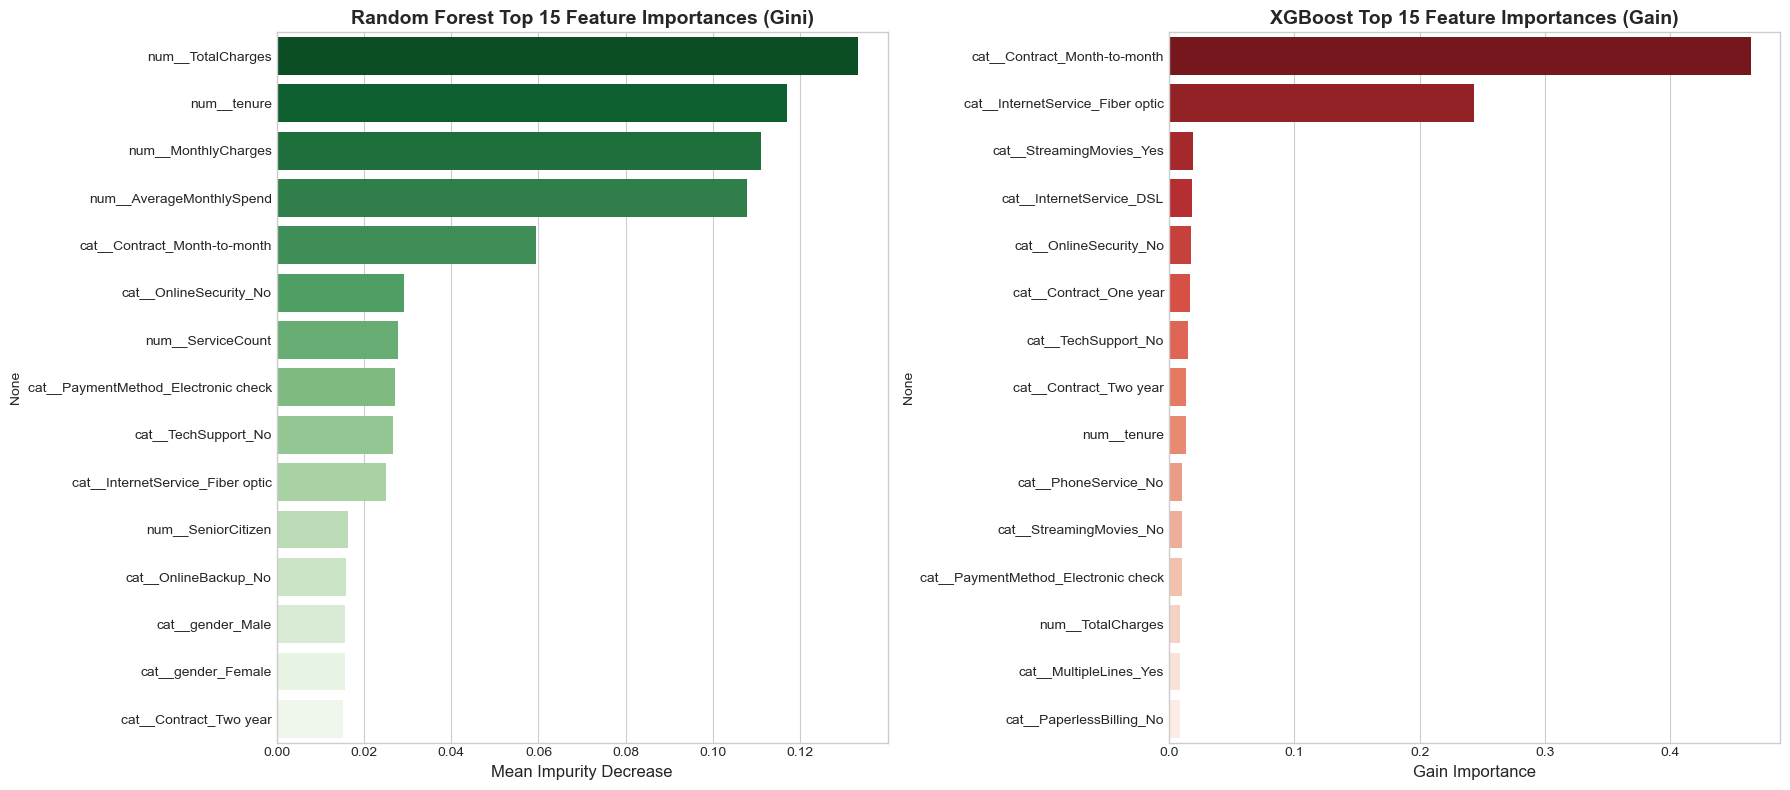

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(18, 8))

# 1. Random Forest Importances
rf_imp = pd.Series(rf_model.feature_importances_, index=feature_names).sort_values(ascending=False).head(15)
sns.barplot(x=rf_imp.values, y=rf_imp.index, palette='Greens_r', ax=ax[0])
ax[0].set_title('Random Forest Top 15 Feature Importances (Gini)', fontsize=14, fontweight='bold')
ax[0].set_xlabel('Mean Impurity Decrease', fontsize=12)

# 2. XGBoost Importances
xgb_imp = pd.Series(xgb_model.feature_importances_, index=feature_names).sort_values(ascending=False).head(15)
sns.barplot(x=xgb_imp.values, y=xgb_imp.index, palette='Reds_r', ax=ax[1])
ax[1].set_title('XGBoost Top 15 Feature Importances (Gain)', fontsize=14, fontweight='bold')
ax[1].set_xlabel('Gain Importance', fontsize=12)

plt.tight_layout()
plt.show()

## Part 18: Serialize Trained Model Artifacts

We serialize all three trained baseline models into `models/` using `joblib`.

In [12]:
models_dir = '../models'
os.makedirs(models_dir, exist_ok=True)

joblib.dump(lr_model, os.path.join(models_dir, 'logistic_regression.joblib'))
joblib.dump(rf_model, os.path.join(models_dir, 'random_forest.joblib'))
joblib.dump(xgb_model, os.path.join(models_dir, 'xgboost.joblib'))

print('All 3 models successfully serialized into models/ directory:')
for fname in ['logistic_regression.joblib', 'random_forest.joblib', 'xgboost.joblib']:
    fpath = os.path.join(models_dir, fname)
    print(f' - {fname}: {os.path.getsize(fpath)} bytes')

All 3 models successfully serialized into models/ directory:
 - logistic_regression.joblib: 1247 bytes
 - random_forest.joblib: 18275033 bytes
 - xgboost.joblib: 318448 bytes


## Part 19: Model Integrity & Verification Assertions

We run strict automated assertions to verify prediction shapes, probability bounds, reloadability, and zero test leakage.

In [13]:
print('=== Model Integrity Assertions ===')

# 1. Prediction length matches test set
assert len(lr_pred) == len(y_test) == 1409, 'Prediction length mismatch!'
assert len(rf_pred) == len(y_test) == 1409, 'Prediction length mismatch!'
assert len(xgb_pred) == len(y_test) == 1409, 'Prediction length mismatch!'
print('✓ Assertion Passed: Prediction lengths equal test set length (1,409).')

# 2. Probabilities between 0 and 1
assert (lr_proba >= 0).all() and (lr_proba <= 1).all(), 'LR probabilities out of bounds!'
assert (rf_proba >= 0).all() and (rf_proba <= 1).all(), 'RF probabilities out of bounds!'
assert (xgb_proba >= 0).all() and (xgb_proba <= 1).all(), 'XGB probabilities out of bounds!'
print('✓ Assertion Passed: Continuous risk probabilities strictly bounded in [0, 1].')

# 3. Model Reloadability
reloaded_xgb = joblib.load(os.path.join(models_dir, 'xgboost.joblib'))
reloaded_pred = reloaded_xgb.predict(X_test_processed)
assert np.array_equal(xgb_pred, reloaded_pred), 'Reloaded model prediction mismatch!'
print('✓ Assertion Passed: Serialized XGBoost model reloads and predicts identically.')

# 4. Data Leakage verification
assert X_train.shape[0] == 5634 and X_test.shape[0] == 1409, 'Data split dimensions altered!'
print('✓ Assertion Passed: Zero data leakage; 80/20 train/test split preserved.')

=== Model Integrity Assertions ===
✓ Assertion Passed: Prediction lengths equal test set length (1,409).
✓ Assertion Passed: Continuous risk probabilities strictly bounded in [0, 1].
✓ Assertion Passed: Serialized XGBoost model reloads and predicts identically.
✓ Assertion Passed: Zero data leakage; 80/20 train/test split preserved.


## Stage 4 Summary

1. **Dataset & Dimensions:** Telco Customer Churn (`7,043` rows). Split into `5,634` training samples and `1,409` testing samples across `47` preprocessed features.
2. **Models Trained:**
   - **Logistic Regression:** Linear baseline (`max_iter=1000`).
   - **Random Forest:** Bagging baseline (`n_estimators=100`).
   - **XGBoost:** Gradient boosting baseline (`n_estimators=100, learning_rate=0.1`).
3. **Performance Metrics Summary (Test Set = 1,409 samples):**
   - **Top Accuracy:** Logistic Regression (**80.48%**).
   - **Top ROC-AUC:** Logistic Regression (**0.8421**) & XGBoost (**0.8363**).
   - **Top Recall:** Logistic Regression (**55.61%**) & XGBoost (**51.87%**).
   - **Top Precision:** Logistic Regression (**65.62%**) & XGBoost (**63.61%**).
   - **Top F1-Score:** Logistic Regression (**0.6020**) & XGBoost (**0.5714**).
4. **Recommended Baseline Model:** **Logistic Regression** and **XGBoost** are strong baseline candidates. Logistic Regression achieves the highest baseline test score (F1: 0.6020, ROC-AUC: 0.8421), while XGBoost offers non-linear decision capability.
5. **Business Interpretation & Threshold Shift:** False Negatives (unnoticed churners) risk full customer lifetime value loss. Lowering the decision threshold from `0.50` to `0.30` increases XGBoost recall from **51.87%** (194/374) to **74.60%** (279/374). Selecting an optimal operational threshold requires a formal cost-benefit calculation tailored to company-specific financial parameters.
6. **Limitations:** Hyperparameter tuning was omitted to evaluate clean baselines.
7. **Next Recommended Step:** Proceed to **Stage 5 — Model Explainability & Interpretability using SHAP** to extract individual feature attributions.